# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Nina Breen, Marin Marcillac, Claire McGinn, Roney Nguyen

**Date:** 11/9/26

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.

In [2]:
# Your Phase 1 solution to the problem goes here.
import pandas as pd
df = pd.read_csv('data/pierce_county_house_sales.csv')
df = df.copy() 
df.head(5)

,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [3]:
df.info()
display(df['view_quality'].unique())
df['waterfront_type'].unique()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

<ArrowStringArray>
[          nan,    'View Avg',  'View Lim -',    'View Lim',   'View Good',
  'View Avg +',  'View Lim +', 'View V-Good', 'View Good +']
Length: 9, dtype: str

<ArrowStringArray>
[nan, 'WF Lake', 'WF Salt', 'WF Stream/Creek', 'WF River']
Length: 5, dtype: str

In [4]:
# filling missing values with 'none'
df['view_quality'] = df['view_quality'].fillna('none')
df['waterfront_type'] = df['waterfront_type'].fillna('none')

array([[<Axes: title={'center': 'sale_price'}>,
        <Axes: title={'center': 'house_square_feet'}>,
        <Axes: title={'center': 'attic_finished_square_feet'}>],
       [<Axes: title={'center': 'basement_square_feet'}>,
        <Axes: title={'center': 'attached_garage_square_feet'}>,
        <Axes: title={'center': 'detached_garage_square_feet'}>],
       [<Axes: title={'center': 'fireplaces'}>,
        <Axes: title={'center': 'stories'}>,
        <Axes: title={'center': 'year_built'}>],
       [<Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'bathrooms'}>, <Axes: >]], dtype=object)

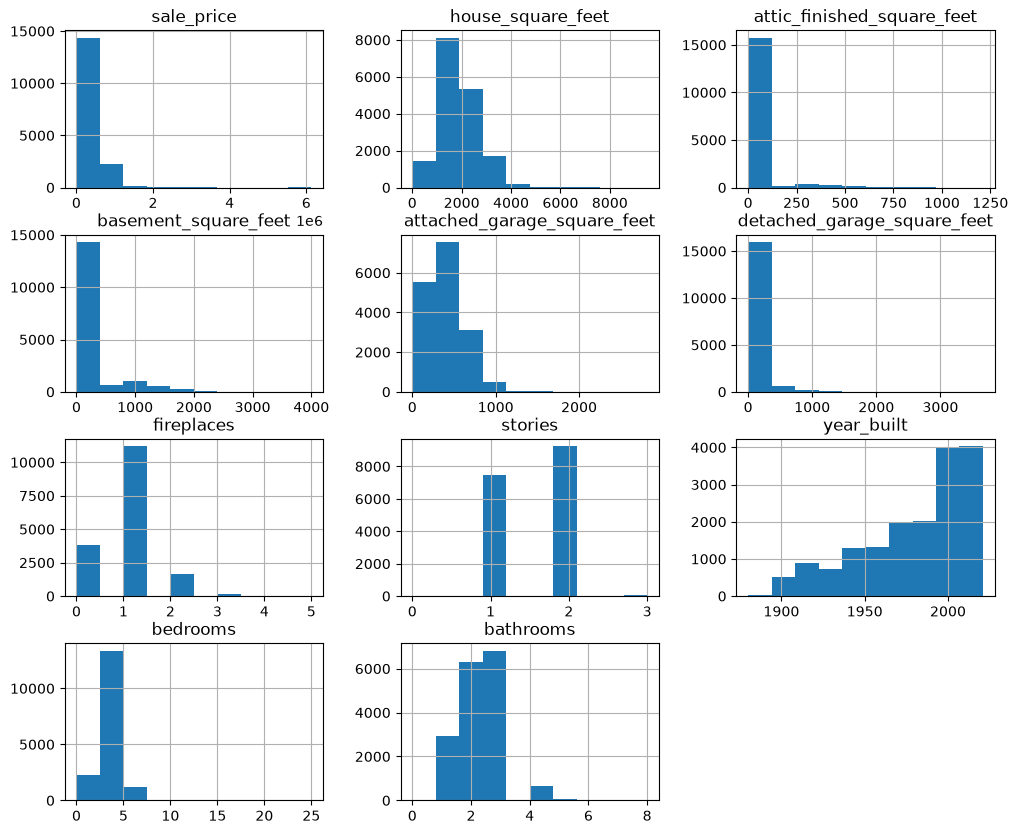

In [5]:
df.hist(figsize=(12, 10))

2. Transform your variables - particularly categorical ones - for use in your regression analysis.

In [6]:
df = df.drop(columns=['sale_date'])


In [7]:
df_reg = pd.get_dummies(df, drop_first = True, dtype=int)

df_reg.info()

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 56 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   sale_price                               16814 non-null  int64
 1   house_square_feet                        16814 non-null  int64
 2   attic_finished_square_feet               16814 non-null  int64
 3   basement_square_feet                     16814 non-null  int64
 4   attached_garage_square_feet              16814 non-null  int64
 5   detached_garage_square_feet              16814 non-null  int64
 6   fireplaces                               16814 non-null  int64
 7   stories                                  16814 non-null  int64
 8   year_built                               16814 non-null  int64
 9   bedrooms                                 16814 non-null  int64
 10  bathrooms                                16814 non-null  int64
 11  hvac_descript

3. Implement an 80/20 train-test split. Put the test data aside.

In [8]:
from sklearn.model_selection import train_test_split
eval_x_raw = df_reg.drop(columns = ['sale_price'])
eval_y = df_reg['sale_price']
(x_train, x_test, y_train, y_test,) = train_test_split(eval_x_raw, eval_y, test_size = 0.20, random_state = 7)

4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?

In [9]:
# Linear model - all features
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import root_mean_squared_error
import numpy as np
model = LinearRegression() 
model.fit(x_train, y_train) 
print("R-squared - train:", round(model.score(x_train, y_train), 4))
print("R-squared - test:", round(model.score(x_test, y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train)), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test)), 4))

R-squared - train: 0.5352
R-squared - test: 0.5321
RMSE - train: 163846.6694
RMSE - test: 149319.5406


In [10]:
# Linear model - int features
features = ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))


R-squared - train: 0.3965
R-squared - test: 0.4341
RMSE - train: 186688.0336
RMSE - test: 164216.9435


In [11]:
# linear model - categorical features
features = ['hvac_description_Electric Baseboard',
  'hvac_description_Floor Wall Furnace',
  'hvac_description_Floor/Wall Furnace',
  'hvac_description_Forced Air',
  'hvac_description_Heat Pump',
  'hvac_description_Hot Water Baseboard',
  'hvac_description_No Heat',
  'hvac_description_Warm and Cool Air Zone',
  'exterior_Cedar Finished Cabin',
  'exterior_Cedar Unfinished Cabin',
  'exterior_Finished Cottage',
  'exterior_Frame Hardboard',
  'exterior_Frame Rustic Log',
  'exterior_Frame Siding',
  'exterior_Frame Stucco',
  'exterior_Frame Vinyl',
  'exterior_Log',
  'exterior_Masonry Common Brick',
  'exterior_Masonry Concrete Block',
  'exterior_Pine A-Frame',
  'exterior_Pine Finished Cabin',
  'exterior_Pine Unfinished Cabin',
  'exterior_Unfinished Cottage',
  'interior_Paneling',
  'roof_cover_Composition Shingle',
  'roof_cover_Concrete Tile',
  'roof_cover_Formed Seam Metal',
  'roof_cover_Preformed Metal',
  'roof_cover_Wood Shake',
  'waterfront_type_WF River',
  'waterfront_type_WF Salt',
  'waterfront_type_WF Stream/Creek',
  'waterfront_type_none',
  'view_quality_View Avg +',
  'view_quality_View Good',
  'view_quality_View Good +',
  'view_quality_View Lim',
  'view_quality_View Lim +',
  'view_quality_View Lim -',
  'view_quality_View V-Good',
  'view_quality_none',
  'utility_sewer_SEWER/SEPTIC AVAIL',
  'utility_sewer_SEWER/SEPTIC INSTALLED',
  'utility_sewer_SEWER/SEPTIC NO',
  'utility_sewer_SEWER/SEPTIC NO PERC'
]
model = LinearRegression() 
model.fit(x_train[features], y_train) 
print("R-squared - train:", round(model.score(x_train[features], y_train), 4))
print("R-squared - test:", round(model.score(x_test[features], y_test), 4))

print('RMSE - train:', round(root_mean_squared_error(y_train, model.predict(x_train[features])), 4))
print('RMSE - test:', round(root_mean_squared_error(y_test, model.predict(x_test[features])), 4))

R-squared - train: 0.3347
R-squared - test: 0.3017
RMSE - train: 196018.2255
RMSE - test: 182416.6656


In [12]:
# The model that has all of the features does the best based on R-squared and RMSE metrics. It has the lowest RMSE value and the highest R-squared.

5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 

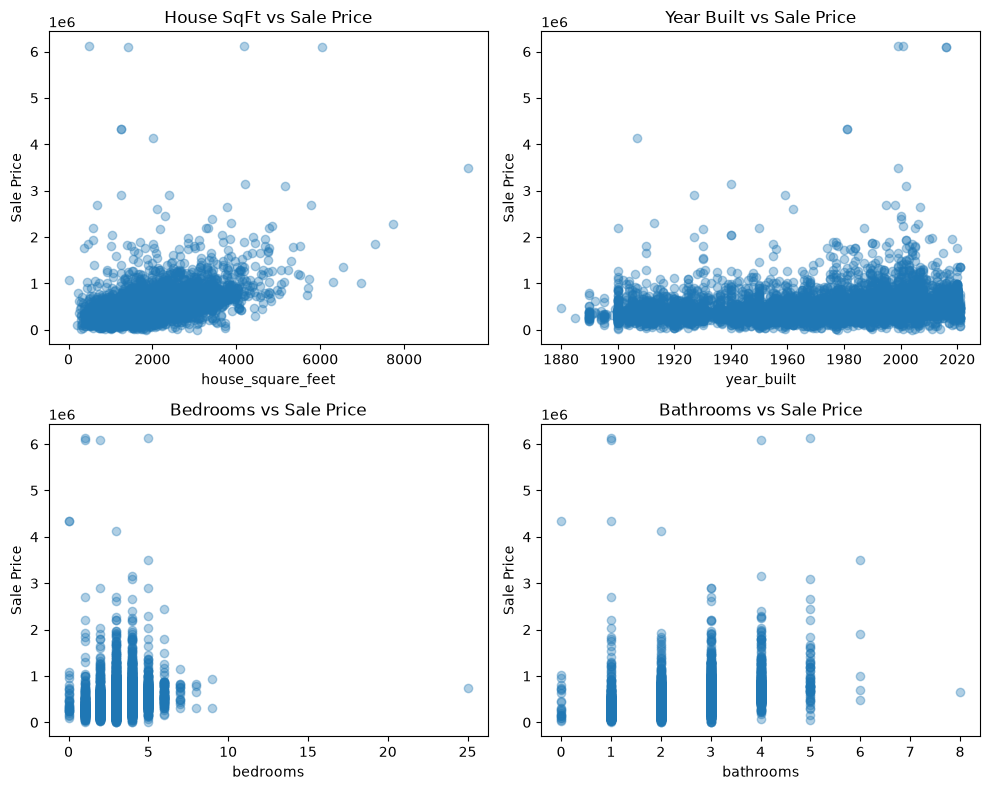

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].scatter(x_train['house_square_feet'], y_train, alpha=0.35)
axes[0, 0].set_title("House SqFt vs Sale Price")
axes[0, 0].set_xlabel("house_square_feet")
axes[0, 0].set_ylabel("Sale Price")

axes[0, 1].scatter(x_train['year_built'], y_train, alpha=0.35)
axes[0, 1].set_title("Year Built vs Sale Price")
axes[0, 1].set_xlabel("year_built")
axes[0, 1].set_ylabel("Sale Price")

axes[1, 0].scatter(x_train['bedrooms'], y_train, alpha=0.35)
axes[1, 0].set_title("Bedrooms vs Sale Price")
axes[1, 0].set_xlabel("bedrooms")
axes[1, 0].set_ylabel("Sale Price")

axes[1, 1].scatter(x_train['bathrooms'], y_train, alpha=0.35)
axes[1, 1].set_title("Bathrooms vs Sale Price")
axes[1, 1].set_xlabel("bathrooms")
axes[1, 1].set_ylabel("Sale Price")

plt.tight_layout()
plt.show()

In [14]:
#Yes, I notice some non-linearities here. In the house square feet and year built plots
 # the data points don't just form a straight line, the spread of sale prices are wider
# as the houses get bigger and newer, which means a simple straight line doesn't capture the whole pattern.


6. Include transformations and interactions of your variables, and build xa more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?

In [15]:
# I used PolynomialFeatures to easily build out the squared terms and interaction products easier like on the slides. 
# the house features work together to determine the value and price of the house

from sklearn.preprocessing import PolynomialFeatures

num_data = ['house_square_feet', 'year_built', 'bedrooms', 'bathrooms']
expander = PolynomialFeatures(degree=2, include_bias=False)
train_expanded = expander.fit_transform(x_train[num_data])
test_expanded = expander.transform(x_test[num_data])
x_train_poly = pd.DataFrame(train_expanded, columns=expander.get_feature_names_out(), index=x_train.index)
x_test_poly = pd.DataFrame(test_expanded, columns=expander.get_feature_names_out(), index=x_test.index)
x_train_cat = x_train.drop(columns=num_data)
x_test_cat = x_test.drop(columns=num_data)
x_train_complex = pd.concat([x_train_cat, x_train_poly], axis=1)
x_test_complex = pd.concat([x_test_cat, x_test_poly], axis=1)
complex_model = LinearRegression()
complex_model.fit(x_train_complex, y_train)
print("Complex Model R-squared - train:", round(complex_model.score(x_train_complex, y_train), 4))
print("Complex Model R-squared - test:", round(complex_model.score(x_test_complex, y_test), 4))

print('Complex Model RMSE - train:', round(root_mean_squared_error(y_train, complex_model.predict(x_train_complex)), 4))
print('Complex Model RMSE - test:', round(root_mean_squared_error(y_test, complex_model.predict(x_test_complex)), 4))



Complex Model R-squared - train: 0.4048
Complex Model R-squared - test: 0.4388
Complex Model RMSE - train: 185406.6085
Complex Model RMSE - test: 163527.1001


In [16]:
# COMPARISON:
# This complex model did a lot better than the simple ones from Question 4 
# The test R-squared went up to 0.4388 and the test RMSE dropped down to $163,527.
# it fit the  patterns we saw in the scatter plots
# Also, since our test R-squared (0.4388) is actually slightly higher than our train 
# R-squared (0.4048), I believe the data isn't overfit 


7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?

In [17]:
# SUMMARY:
# My simple categorical model definitely underfit the data. With a 
# test R-squared of only 0.3017, it was just too basic to catch the real pricing patterns.
#  I didn't really see overfitting (where the model just memorizes the 
# training data). But I did test cranking the polynomial degree up to 6 to see what would 
# happen! Instead of helping, the extra math just made things worse. The test R-squared 
# dropped from 0.4388 at degree 2 down to 0.3507 at degree 6, and the error went up. 
# I learned you pick from the test set, not the training set. 
# Sometimes making a  model more complex doesn't always make it better!


8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

In [19]:
from sklearn.linear_model import Lasso
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
#https://scikit-learn.org/0.15/modules/generated/sklearn.linear_model.Lasso.html
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html
#https://www.geeksforgeeks.org/machine-learning/implementation-of-lasso-regression-from-scratch-using-python/

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_complex)
x_test_scaled = scaler.transform(x_test_complex)
lasso_model = Lasso(max_iter=10000)
lasso_model.fit(x_train_scaled, y_train)
print("Lasso Model R-squared - train:", round(lasso_model.score(x_train_scaled, y_train), 4))
print("Lasso Model R-squared - test:", round(lasso_model.score(x_test_scaled, y_test), 4))

print('Lasso Model RMSE - train:', round(root_mean_squared_error(y_train, lasso_model.predict(x_train_scaled)), 4))
print('Lasso Model RMSE - test:', round(root_mean_squared_error(y_test, lasso_model.predict(x_test_scaled)), 4))

coefs = lasso_model.coef_

print(coefs)

len(coefs)


# The Lasso model gave a test R-squared of 0.5342 and a test RMSE of 148,978.61. 
# I printed the raw coefficients array and its length. 
#There were 65 total features (len(coefs) = 65).I looked at the printed array. 
# It kept almost all of them, but it successfully zeroed out exactly one feature (showing as 0.00000000e+00). 
# Therefore, the Lasso model selected 64 out of the 65 total features


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Lasso Model R-squared - train: 0.5493
Lasso Model R-squared - test: 0.5342
Lasso Model RMSE - train: 161327.2445
Lasso Model RMSE - test: 148978.6072
[ 1.15498195e+04  3.98140797e+04  2.09809665e+04  1.13928753e+04
  8.52700706e+03 -1.31959597e+04 -1.70415094e+05 -3.71983677e+03
 -4.66264777e+04 -2.23708812e+05 -1.39117287e+05 -4.42285704e+04
 -4.08758790e+04 -1.13079877e+05 -2.17412750e+04 -9.11382101e+03
 -3.90156290e+04 -2.14836705e+04 -1.92446343e+04 -3.36238546e+05
 -9.29907316e+04 -3.12443738e+05 -4.86985940e+03 -1.04214692e+05
 -4.84574752e+04 -7.83506537e+03 -1.05348422e+04 -2.15816384e+04
 -7.39422967e+03 -1.21187967e+04 -2.55252804e+02  1.66180449e+03
  1.02936733e+03 -1.21586599e+02  8.06336675e+02 -1.52922366e+04
  3.18703161e+04 -2.53354281e+04 -5.79601840e+04  7.74992755e+03
  3.90790956e+03  4.52603770e+03 -4.48229567e+

/Users/marinmarcillac/miniconda3/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.692576e+14, tolerance: 7.768e+10
  model = cd_fast.enet_coordinate_descent(


65

In [20]:
#We can see the coef on the data

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]